# Exploratory Data Analysis: `games.csv` (FronkonGames/steam-games-dataset)
**Source:** Hugging Face, `FronkonGames/steam-games-dataset` (MIT licence per the repo page). The file is a scraped copy of Steam store pages.

The page claims about 124k rows and 41 columns. The notebook **discovers the columns first** and maps them to roles, so a renamed column does not break it. Any section whose role is missing is skipped.

**Known issue handled in section 2:** the header of this file has 39 names for 40 data fields (`Discount` and `DLC count` are glued together), which labels every later column one position off. The notebook repairs the header before loading.

**Questions this notebook answers**
1. What columns exist, and is the header aligned with the data?
2. How many rows are real games (not playtests, demos, soundtracks or empty placeholders)?
3. How many games have enough reviews for a label, and what is the class balance under different rules?
4. Which columns are post-launch (leakage)?
5. How long is the description text?
6. Release-year coverage, developer clustering, and overlap with the project's current Steam data.

Safety: URL and e-mail columns are **not loaded**. Open the CSV with pandas only (not Excel), and do not click links from the data.

## 1. Setup

In [23]:
import os, re, csv, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 60)
plt.rcParams['figure.figsize'] = (9, 4.5)

LOCAL_PATH = 'games.csv'          # path to the downloaded file
LOAD_ROWS = None                  # e.g. 20_000 for a quick trial, None = everything
PROJECT_STEAM_PATH = r'C:\Users\3214h\Documents\fyp-steam-reception\data\raw\Dataset-2.csv'         # optional: path to the project's current Steam data (csv or parquet) for the overlap check
PROJECT_STEAM_ID_COL = 'appid'       # optional: its id column name (e.g. 'appid')

assert os.path.exists(LOCAL_PATH), f'{LOCAL_PATH} not found. Download games.csv first.'
print(LOCAL_PATH, '|', round(os.path.getsize(LOCAL_PATH) / 1e6, 1), 'MB')

games.csv | 401.1 MB


## 2. Schema discovery and header check

In [2]:
# This file's header has 39 names but each data row has 40 fields: the header glues 'Discount' and
# 'DLC count' into one name ('DiscountDLC count'). Everything after that point is then labelled one column off.
with open(LOCAL_PATH, newline='', encoding='utf-8', errors='replace') as f:
    rd = csv.reader(f)
    header = next(rd)
    widths = pd.Series([len(r) for _, r in zip(range(2000), rd)]).value_counts()
print('header fields:', len(header))
print('fields per data row (first 2000 rows):', widths.to_dict())

FIXED = list(header)
if 'DiscountDLC count' in FIXED and widths.idxmax() == len(header) + 1:
    i = FIXED.index('DiscountDLC count')
    FIXED[i:i+1] = ['Discount', 'DLC count']
    print('Repaired header: split "DiscountDLC count" into "Discount" and "DLC count".')
elif widths.idxmax() != len(header):
    print('WARNING: header and data widths differ and the known repair does not apply. Column names may be shifted.')
assert len(FIXED) == widths.idxmax(), 'Header still does not match the data width. Stop and inspect the file by eye.'

peek = pd.read_csv(LOCAL_PATH, skiprows=1, names=FIXED, nrows=5, index_col=False)
print(len(peek.columns), 'columns')
print(list(peek.columns))
peek.T

header fields: 39
fields per data row (first 2000 rows): {40: 2000}
Repaired header: split "DiscountDLC count" into "Discount" and "DLC count".
40 columns
['AppID', 'Name', 'Release date', 'Estimated owners', 'Peak CCU', 'Required age', 'Price', 'Discount', 'DLC count', 'About the game', 'Supported languages', 'Full audio languages', 'Reviews', 'Header image', 'Website', 'Support url', 'Support email', 'Windows', 'Mac', 'Linux', 'Metacritic score', 'Metacritic url', 'User score', 'Positive', 'Negative', 'Score rank', 'Achievements', 'Recommendations', 'Notes', 'Average playtime forever', 'Average playtime two weeks', 'Median playtime forever', 'Median playtime two weeks', 'Developers', 'Publishers', 'Categories', 'Genres', 'Tags', 'Screenshots', 'Movies']


,0,1,2,3,4
AppID,2539430,496350,1034400,3292190,3631080
Name,Black Dragon Mage Playtest,Supipara - Chapter 1 Spring Has Come!,Mystery Solitaire The Black Raven,버튜버 파라노이아 - Vtuber Paranoia,Maze Quest VR
Release date,"Aug 1, 2023","Jul 29, 2016","May 6, 2019","Oct 31, 2024","Apr 24, 2025"
Estimated owners,0 - 0,0 - 20000,0 - 20000,0 - 20000,0 - 20000
Peak CCU,0,0,0,1,0
Required age,0,0,0,0,0
Price,0.0,5.24,4.99,8.99,4.99
Discount,0,65,0,0,0
DLC count,0,0,0,1,0
About the game,NaN,"Springtime, April: when the cherry trees come into full ...","Immerse yourself in the most beloved, mystical and entra...","synopsis 'Hello, I'm Hiyoro, a new YouTuber!' It's been ...",Its not just a Maze; its a Quest! Enter the captivating ...


In [3]:
n_rows = 0
for chunk in pd.read_csv(LOCAL_PATH, usecols=[0], chunksize=200_000, index_col=False, skiprows=1, header=None):
    n_rows += len(chunk)
print(f'{n_rows:,} rows (page claims about 124k)')

125,855 rows (page claims about 124k)


## 3. Load (URL and e-mail columns are skipped on purpose)

In [4]:
SKIP = re.compile(r'(url|website|email|link|image|screenshot|movie|video|header)', re.I)
all_cols = list(FIXED)
keep = [c for c in all_cols if not SKIP.search(str(c))]
print('skipped:', [c for c in all_cols if c not in keep])

df = pd.read_csv(LOCAL_PATH, skiprows=1, names=FIXED, usecols=keep, nrows=LOAD_ROWS, index_col=False, low_memory=False)
print(df.shape)
print(f'{df.memory_usage(deep=True).sum() / 1e6:.0f} MB in memory')
df.head(3).T

skipped: ['Header image', 'Website', 'Support url', 'Support email', 'Metacritic url', 'Screenshots', 'Movies']
(125855, 33)
238 MB in memory


,0,1,2
AppID,2539430,496350,1034400
Name,Black Dragon Mage Playtest,Supipara - Chapter 1 Spring Has Come!,Mystery Solitaire The Black Raven
Release date,"Aug 1, 2023","Jul 29, 2016","May 6, 2019"
Estimated owners,0 - 0,0 - 20000,0 - 20000
Peak CCU,0,0,0
Required age,0,0,0
Price,0.0,5.24,4.99
Discount,0,65,0
DLC count,0,0,0
About the game,NaN,"Springtime, April: when the cherry trees come into full ...","Immerse yourself in the most beloved, mystical and entra..."


## 4. Column-role mapping
Each role lists several likely names. Check the printout and edit `COL` by hand if a role is wrong.

In [5]:
def norm(s):
    return re.sub(r'[^a-z0-9]', '', str(s).lower())

def find_col(*cands):
    lookup = {norm(c): c for c in df.columns}
    for cand in cands:
        if norm(cand) in lookup:
            return lookup[norm(cand)]
    return None

COL = {
    'id':        find_col('appid', 'app_id', 'id', 'steam_appid'),
    'name':      find_col('name', 'title'),
    'release':   find_col('release_date', 'releasedate', 'released'),
    'price':     find_col('price', 'initial_price', 'price_overview'),
    'dev':       find_col('developers', 'developer'),
    'pub':       find_col('publishers', 'publisher'),
    'genres':    find_col('genres'),
    'tags':      find_col('tags', 'steamspy_tags'),
    'cats':      find_col('categories'),
    'desc_s':    find_col('short_description', 'shortdescription'),
    'desc_l':    find_col('detailed_description', 'about_the_game', 'aboutthegame', 'about'),
    'pos':       find_col('positive', 'positive_ratings'),
    'neg':       find_col('negative', 'negative_ratings'),
    'recs':      find_col('recommendations'),
    'owners':    find_col('estimated_owners', 'owners'),
    'ccu':       find_col('peak_ccu', 'peakccu'),
    'playtime':  find_col('average_playtime_forever', 'average_playtime', 'avg_playtime_forever'),
    'meta':      find_col('metacritic_score'),
    'user_score':find_col('user_score'),
    'score_rank':find_col('score_rank'),
    'ach':       find_col('achievements'),
    'dlc':       find_col('dlc_count', 'dlccount'),
    'discount':  find_col('discount'),
    'age':       find_col('required_age', 'requiredage'),
    'langs':     find_col('supported_languages', 'languages'),
    'win':       find_col('windows'),
    'mac':       find_col('mac'),
    'linux':     find_col('linux'),
    'notes':     find_col('notes'),
    'reviews_txt': find_col('reviews'),
}
for k, v in COL.items():
    print(f'{k:12s} -> {v}')
unmapped = [c for c in df.columns if c not in COL.values()]
print('\nnot mapped:', unmapped)

# Sanity checks: a shifted header shows up as text in numeric roles or numbers in text roles
def share_numeric(c): return pd.to_numeric(df[c].dropna().astype(str).head(2000), errors='coerce').notna().mean()
checks = {'desc_l': 'text', 'name': 'text', 'pos': 'number', 'neg': 'number', 'price': 'number', 'dlc': 'number', 'win': 'bool', 'dev': 'text'}
for role, kind in checks.items():
    c = COL.get(role)
    if not c: continue
    sh = share_numeric(c)
    bad = (kind == 'text' and sh > 0.5) or (kind == 'number' and sh < 0.9)
    print(f'{role:8s} {c!r:28s} numeric share {sh:.2f}  {"<-- CHECK: looks wrong" if bad else "ok"}')

id           -> AppID
name         -> Name
release      -> Release date
price        -> Price
dev          -> Developers
pub          -> Publishers
genres       -> Genres
tags         -> Tags
cats         -> Categories
desc_s       -> None
desc_l       -> About the game
pos          -> Positive
neg          -> Negative
recs         -> Recommendations
owners       -> Estimated owners
ccu          -> Peak CCU
playtime     -> Average playtime forever
meta         -> Metacritic score
user_score   -> User score
score_rank   -> Score rank
ach          -> Achievements
dlc          -> DLC count
discount     -> Discount
age          -> Required age
langs        -> Supported languages
win          -> Windows
mac          -> Mac
linux        -> Linux
notes        -> Notes
reviews_txt  -> Reviews

not mapped: ['Full audio languages', 'Average playtime two weeks', 'Median playtime forever', 'Median playtime two weeks']
desc_l   'About the game'             numeric share 0.00  ok
name     'Name'    

## 5. Profile: missing values, empty strings, zeros, duplicates

In [6]:
rows = []
for c in df.columns:
    s = df[c]
    empty = int((s.astype(str).str.strip().isin(['', '[]', '{}', 'nan', 'None'])).sum())
    zeros = int((pd.to_numeric(s, errors='coerce') == 0).sum()) if s.dtype != object else 0
    rows.append({'column': c, 'dtype': str(s.dtype), 'null_%': round(s.isna().mean()*100, 2),
                 'empty_or_blank_%': round(empty/len(df)*100, 2), 'zero_%': round(zeros/len(df)*100, 2),
                 'unique': int(s.nunique(dropna=True)),
                 'role': next((k for k, v in COL.items() if v == c), '')})
profile = pd.DataFrame(rows)
profile

,column,dtype,null_%,empty_or_blank_%,zero_%,unique,role
0,AppID,int64,0.00,0.00,0.00,125855,id
1,Name,str,0.00,0.00,0.00,124644,name
2,Release date,str,0.00,0.00,0.00,5141,release
3,Estimated owners,str,0.00,0.00,0.00,14,owners
4,Peak CCU,int64,0.00,0.00,84.36,1110,ccu
5,Required age,int64,0.00,0.00,98.98,15,age
6,Price,float64,0.00,0.00,21.18,953,price
7,Discount,int64,0.00,0.00,67.57,88,discount
8,DLC count,int64,0.00,0.00,85.67,117,dlc
9,About the game,str,6.72,0.00,0.00,116776,desc_l


In [7]:
if COL['id']:
    print('duplicate ids:', int(df[COL['id']].duplicated().sum()))
if COL['name']:
    print('duplicate names:', int(df[COL['name']].duplicated().sum()), '(different games can share a name)')
print('fully duplicated rows:', int(df.duplicated().sum()))

duplicate ids: 0
duplicate names: 1210 (different games can share a name)
fully duplicated rows: 0


## 6. Parsing and derived features
Derived columns start with `x_`. Raw columns are not changed.

In [8]:
def n_items(s):
    # counts list items in a string such as 'A,B,C', \"['A','B']\" or \"{'A': 1, 'B': 2}\"
    s = s.fillna('').astype(str).str.strip()
    out = np.where(s.str.startswith('{'), s.str.count(':'),
          np.where(s.isin(['', '[]', 'nan', 'None']), 0, s.str.count(',') + 1))
    return pd.Series(out, index=s.index)

def split_items(s):
    s = s.fillna('').astype(str)
    s = s.str.replace(r':\s*\d+', '', regex=True)   # dict-style tags: drop the vote counts
    s = s.str.replace(r'[\[\]\{\}\'\"]', '', regex=True)
    return s.str.split(r'\s*,\s*')

if COL['release']:
    df['x_release'] = pd.to_datetime(df[COL['release']], errors='coerce')
    df['x_year'] = df['x_release'].dt.year
if COL['price']:
    df['x_price'] = pd.to_numeric(df[COL['price']], errors='coerce')
if COL['pos'] and COL['neg']:
    df['x_pos'] = pd.to_numeric(df[COL['pos']], errors='coerce')
    df['x_neg'] = pd.to_numeric(df[COL['neg']], errors='coerce')
    df['x_n_rev'] = df['x_pos'] + df['x_neg']
    df['x_pos_ratio'] = df['x_pos'] / df['x_n_rev'].where(df['x_n_rev'] > 0)
for role in ['desc_s', 'desc_l']:
    if COL[role]:
        t = df[COL[role]].fillna('').astype(str)
        df[f'x_{role}_chars'] = t.str.len()
        df[f'x_{role}_words'] = t.str.split().str.len()
for role in ['genres', 'tags', 'cats', 'langs']:
    if COL[role]:
        df[f'x_n_{role}'] = n_items(df[COL[role]])
if COL['owners']:
    lo = df[COL['owners']].astype(str).str.extract(r'(\d[\d,]*)')[0].str.replace(',', '').astype(float)
    df['x_owners_low'] = lo
if COL['win'] or COL['mac'] or COL['linux']:
    plats = [COL[k] for k in ['win', 'mac', 'linux'] if COL[k]]
    df['x_n_platforms'] = df[plats].astype(str).apply(lambda c: c.str.lower().isin(['true', '1', 'yes'])).sum(axis=1)

print([c for c in df.columns if c.startswith('x_')])

['x_release', 'x_year', 'x_price', 'x_pos', 'x_neg', 'x_n_rev', 'x_pos_ratio', 'x_desc_l_chars', 'x_desc_l_words', 'x_n_genres', 'x_n_tags', 'x_n_cats', 'x_n_langs', 'x_owners_low', 'x_n_platforms']


## 7. Which rows are real games?
The page notes many placeholder rows (zero values, empty descriptions). Playtests, demos and soundtracks may also be present.

In [9]:
n = len(df)
name = df[COL['name']].fillna('').astype(str) if COL['name'] else pd.Series('', index=df.index)
flags = pd.DataFrame(index=df.index)
flags['no_name'] = name.str.strip() == ''
flags['name_has_playtest'] = name.str.contains(r'playtest', case=False)
flags['name_has_demo'] = name.str.contains(r'\bdemo\b', case=False)
flags['name_has_soundtrack_or_ost'] = name.str.contains(r'soundtrack|\bOST\b', case=False)
flags['name_has_dlc_like'] = name.str.contains(r'\bDLC\b|expansion pack|season pass', case=False)
if 'x_release' in df: flags['no_release_date'] = df['x_release'].isna()
if 'x_desc_l_chars' in df: flags['no_long_description'] = df['x_desc_l_chars'] == 0
if 'x_desc_s_chars' in df: flags['no_short_description'] = df['x_desc_s_chars'] == 0
if 'x_n_rev' in df: flags['zero_reviews'] = df['x_n_rev'].fillna(0) == 0
if 'x_n_tags' in df: flags['no_tags'] = df['x_n_tags'] == 0
if 'x_n_genres' in df: flags['no_genres'] = df['x_n_genres'] == 0
summary = pd.DataFrame({'rows': flags.sum(), '%': (flags.mean()*100).round(2)})
display(summary)

,rows,%
no_name,1,0.00
name_has_playtest,8139,6.47
name_has_demo,85,0.07
name_has_soundtrack_or_ost,4,0.00
name_has_dlc_like,4,0.00
no_release_date,0,0.00
no_long_description,8462,6.72
zero_reviews,42899,34.09
no_tags,42502,33.77
no_genres,8423,6.69


In [10]:
# A working definition of 'usable game row'. Edit the rules, then check the count.
mask = ~flags['no_name'] & ~flags['name_has_playtest'] & ~flags['name_has_soundtrack_or_ost']
if 'no_release_date' in flags: mask &= ~flags['no_release_date']
if 'no_long_description' in flags and 'no_short_description' in flags:
    mask &= ~(flags['no_long_description'] & flags['no_short_description'])
df['x_is_game_row'] = mask
print(f'rows kept as game-like: {mask.sum():,} of {n:,} ({mask.mean()*100:.1f}%)')
print('This is a rough filter on names and empty fields. The file has no reliable type column, so demos, DLC and software may remain.')

rows kept as game-like: 117,711 of 125,855 (93.5%)
This is a rough filter on names and empty fields. The file has no reliable type column, so demos, DLC and software may remain.


## 8. Label feasibility
The project label is based on the share of positive reviews. Table: how many rows have at least N reviews, and how balanced the classes are for each cut.

In [11]:
if 'x_pos_ratio' in df:
    g = df[df['x_is_game_row']]
    floors = [1, 10, 25, 50, 100, 500, 1000]
    cuts = [0.70, 0.75, 0.80, 0.85, 0.90]
    out = []
    for fl in floors:
        sub = g[g['x_n_rev'] >= fl]
        row = {'min_reviews': fl, 'games': len(sub), '% of game rows': round(len(sub)/len(g)*100, 1)}
        for c in cuts:
            row[f'pos>={c:.2f}'] = round((sub['x_pos_ratio'] >= c).mean()*100, 1) if len(sub) else np.nan
        out.append(row)
    label_table = pd.DataFrame(out)
    display(label_table)
    print('Cells show the % of games labelled positive. A 50/50 split is the most balanced.')
else:
    print('positive/negative columns not found: label cannot be built from this file')

,min_reviews,games,% of game rows,pos>=0.70,pos>=0.75,pos>=0.80,pos>=0.85,pos>=0.90
0,1,82953,70.5,68.5,62.5,54.2,44.3,34.3
1,10,56661,48.1,71.4,63.3,53.5,41.2,28.8
2,25,40851,34.7,72.9,64.4,53.7,41.0,26.7
3,50,30623,26.0,75.2,66.4,55.1,42.0,26.8
4,100,22803,19.4,77.8,69.3,57.6,43.9,27.9
5,500,10507,8.9,84.4,76.7,65.3,51.4,32.9
6,1000,7209,6.1,86.5,79.5,68.8,55.1,36.3


Cells show the % of games labelled positive. A 50/50 split is the most balanced.


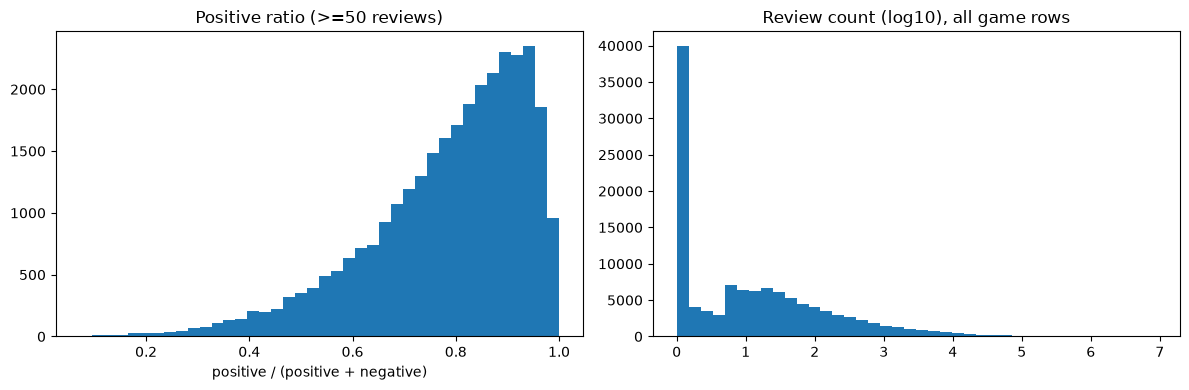

count    30623.000000
mean         0.785306
std          0.154546
min          0.071429
25%          0.700488
50%          0.820456
75%          0.904762
max          1.000000
Name: x_pos_ratio, dtype: float64


In [12]:
if 'x_pos_ratio' in df:
    sub = g[g['x_n_rev'] >= 50]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].hist(sub['x_pos_ratio'], bins=40); ax[0].set_title('Positive ratio (>=50 reviews)'); ax[0].set_xlabel('positive / (positive + negative)')
    ax[1].hist(np.log10(g['x_n_rev'].clip(lower=1)), bins=40); ax[1].set_title('Review count (log10), all game rows')
    plt.tight_layout(); plt.show()
    print(sub['x_pos_ratio'].describe())

## 9. Leakage check
Columns that exist only after launch must not be model inputs. The table lists columns that look post-launch and, where possible, how well each one alone predicts the label (AUC 0.5 = no signal).

In [13]:
POST_ROLES = ['pos', 'neg', 'recs', 'owners', 'ccu', 'playtime', 'meta', 'user_score', 'score_rank', 'reviews_txt']
post = {k: COL[k] for k in POST_ROLES if COL[k]}
print('post-launch columns found:', post)
print('also check: price/DLC/languages/platforms may have changed since launch, because the page shows the store state at scrape time.')

if 'x_pos_ratio' in df:
    try:
        from sklearn.metrics import roc_auc_score
        sub = g[g['x_n_rev'] >= 50].copy()
        y = (sub['x_pos_ratio'] >= 0.80).astype(int)
        res = []
        cand = {k: pd.to_numeric(sub[v], errors='coerce') for k, v in post.items() if k not in ('pos', 'neg', 'reviews_txt')}
        cand['x_owners_low'] = sub.get('x_owners_low')
        cand['x_n_rev'] = sub['x_n_rev']
        for k, s in cand.items():
            if s is None: continue
            m = s.notna()
            if m.sum() > 100 and y[m].nunique() == 2:
                res.append((k, int(m.sum()), round(roc_auc_score(y[m], s[m]), 3)))
        display(pd.DataFrame(res, columns=['column', 'rows', 'AUC vs (ratio >= 0.80)']))
    except Exception as e:
        print('AUC check skipped:', e)

post-launch columns found: {'pos': 'Positive', 'neg': 'Negative', 'recs': 'Recommendations', 'owners': 'Estimated owners', 'ccu': 'Peak CCU', 'playtime': 'Average playtime forever', 'meta': 'Metacritic score', 'user_score': 'User score', 'score_rank': 'Score rank', 'reviews_txt': 'Reviews'}
also check: price/DLC/languages/platforms may have changed since launch, because the page shows the store state at scrape time.


,column,rows,AUC vs (ratio >= 0.80)
0,recs,30623,0.612
1,ccu,30623,0.605
2,playtime,30623,0.524
3,meta,30623,0.521
4,user_score,30623,0.500
5,x_owners_low,30623,0.508
6,x_n_rev,30623,0.591


## 10. Text fields

In [14]:
for role in ['desc_s', 'desc_l']:
    if COL[role]:
        s = df.loc[df['x_is_game_row'], f'x_{role}_words']
        print(f'--- {COL[role]} (words), game rows')
        print(s.describe(percentiles=[.1, .25, .5, .75, .9]).round(1).to_string())
        print('empty:', int((s == 0).sum()), f'({(s == 0).mean()*100:.1f}%)')
if COL['desc_l']:
    ex = df.loc[df['x_is_game_row'], COL['desc_l']].dropna().astype(str)
    print('\nSample long descriptions (first 250 chars):')
    for t in ex.sample(3, random_state=1): print('-', t[:250].replace('\n', ' '))

--- About the game (words), game rows
count    117711.0
mean        214.1
std         166.5
min           0.0
10%          72.0
25%         113.0
50%         177.0
75%         270.0
90%         392.0
max       11530.0
empty: 337 (0.3%)

Sample long descriptions (first 250 chars):
- Welcome To The Conway Estate! Nightdive Studios and Ziggurat Interactive have teamed up to bring back this sophisticated shooter laced with gallows humor and visual violence to bestow mayhem to all! Puzzle solving and strategic thinking are placed at
- This is a 'casual' game on the topic of environmental protection. We will experience its way home from the perspective of a young flying fish. On your way home, we will encounter various new and old obstacles. Sprinting and jumping are two basic abil
- ULTIRE: Balls Out is an action-packed game that is easy to pick up, but requires great precision and decision-making skills to master. Control your ball, collect pickups and avoid obstacles as you compete in dif

In [15]:
# Language check: descriptions may not all be English
if COL['desc_l']:
    t = df.loc[df['x_is_game_row'], COL['desc_l']].dropna().astype(str).sample(min(5000, int(df['x_is_game_row'].sum())), random_state=0)
    ascii_share = t.apply(lambda s: np.mean([ord(ch) < 128 for ch in s[:300]]) if len(s) else 1)
    print(f'descriptions with < 80% ASCII in the first 300 chars (likely non-English): {(ascii_share < 0.8).mean()*100:.1f}% of a 5,000 sample')
    print('HTML tags present:', f"{t.str.contains('<[a-zA-Z]', regex=True).mean()*100:.1f}%", 'of the sample (strip before text models)')

descriptions with < 80% ASCII in the first 300 chars (likely non-English): 1.7% of a 5,000 sample
HTML tags present: 0.0% of the sample (strip before text models)


## 11. Distributions

free games: 15.7%


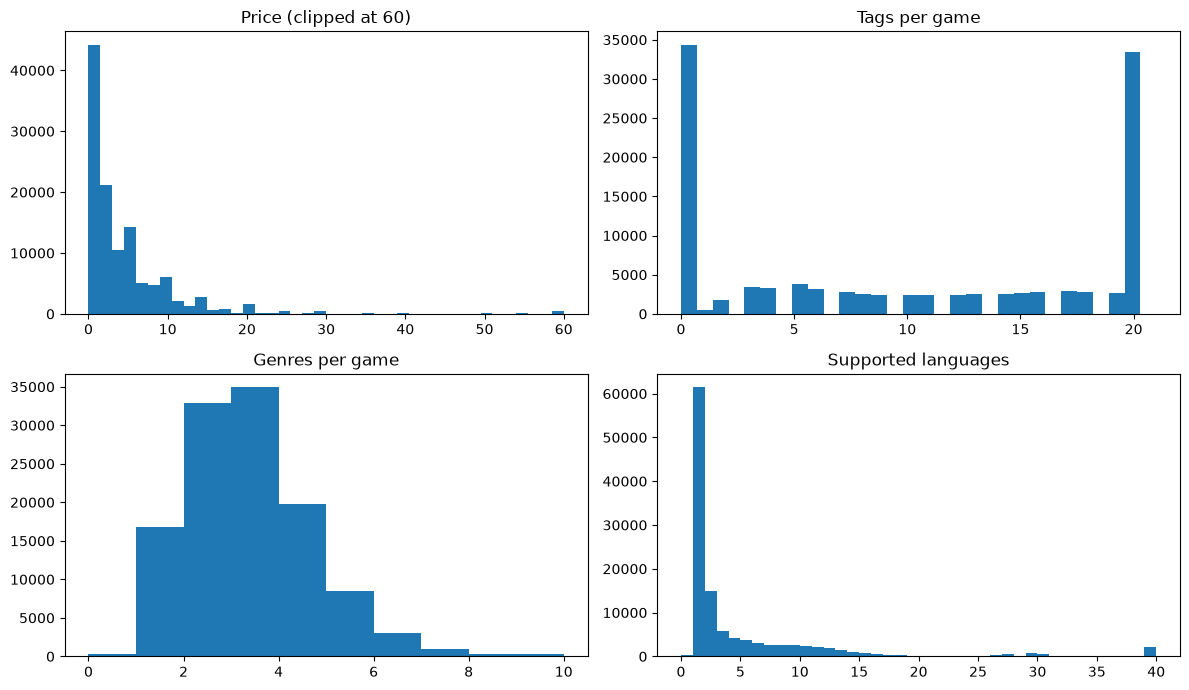

In [16]:
gg = df[df['x_is_game_row']]
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
if 'x_price' in gg:
    ax[0,0].hist(gg['x_price'].clip(upper=60), bins=40); ax[0,0].set_title('Price (clipped at 60)')
    print('free games:', f"{(gg['x_price'] == 0).mean()*100:.1f}%")
if 'x_n_tags' in gg:   ax[0,1].hist(gg['x_n_tags'].clip(upper=30), bins=30); ax[0,1].set_title('Tags per game')
if 'x_n_genres' in gg: ax[1,0].hist(gg['x_n_genres'].clip(upper=10), bins=10); ax[1,0].set_title('Genres per game')
if 'x_n_langs' in gg:  ax[1,1].hist(gg['x_n_langs'].clip(upper=40), bins=40); ax[1,1].set_title('Supported languages')
plt.tight_layout(); plt.show()

In [17]:
for role in ['genres', 'tags']:
    if COL[role]:
        ex = split_items(gg[COL[role]]).explode().str.strip()
        ex = ex[ex != '']
        print(f'--- top 20 {role} (of {ex.nunique():,} distinct)')
        print(ex.value_counts().head(20).to_string())

--- top 20 genres (of 33 distinct)
Genres
Indie                    82874
Casual                   51675
Action                   47335
Adventure                46286
Simulation               24911
Strategy                 23056
RPG                      21575
Free To Play             12603
Early Access             11571
Sports                    4971
Racing                    4169
Massively Multiplayer     2595
Utilities                 1091
Design & Illustration      584
Animation & Modeling       484
Education                  464
Violent                    413
Video Production           340
Game Development           323
Gore                       257
--- top 20 tags (of 452 distinct)
Tags
Singleplayer      50353
Indie             48554
Action            36811
Casual            36565
Adventure         35197
2D                26794
3D                17997
Simulation        17896
Strategy          17850
Puzzle            16370
Atmospheric       16284
RPG               15743
Colorful   

## 12. Time coverage

,games,with_50_reviews,pos_rate_>=0.80
x_year,,,
2007,90,87.0,63.2
2008,158,137.0,63.5
2009,321,259.0,56.8
2010,255,213.0,53.1
2011,260,240.0,46.7
2012,322,309.0,52.4
2013,468,433.0,48.3
2014,1523,1367.0,38.8
2015,2514,1901.0,39.1


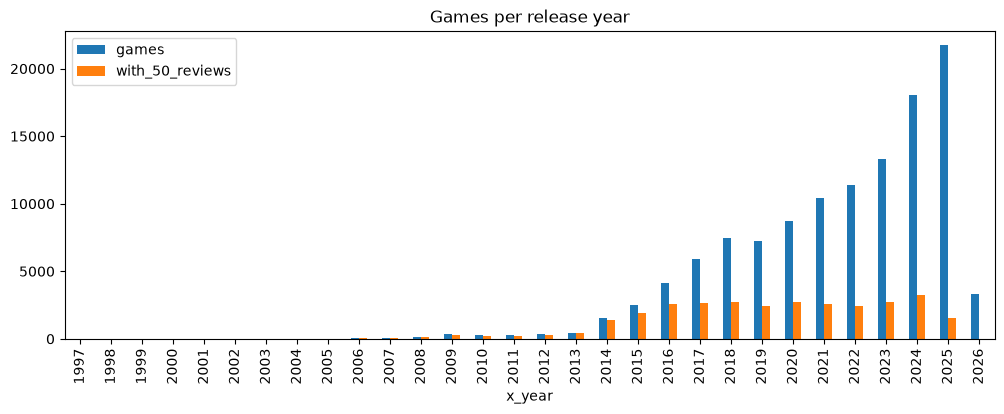

release range: 1997-06-30 00:00:00 to 2026-12-01 00:00:00
future-dated releases: 1 (unreleased or coming-soon games have no real label)


In [18]:
if 'x_year' in gg:
    by = gg.groupby('x_year').agg(games=('x_year', 'size'))
    if 'x_n_rev' in gg:
        by['with_50_reviews'] = gg[gg['x_n_rev'] >= 50].groupby('x_year').size()
        by['pos_rate_>=0.80'] = gg[gg['x_n_rev'] >= 50].groupby('x_year')['x_pos_ratio'].apply(lambda s: round((s >= 0.8).mean()*100, 1))
    by = by.fillna(0)
    display(by.tail(20))
    by[['games'] + (['with_50_reviews'] if 'with_50_reviews' in by else [])].plot(kind='bar', figsize=(12, 4), title='Games per release year')
    plt.show()
    print('release range:', gg['x_release'].min(), 'to', gg['x_release'].max())
    print('future-dated releases:', int((gg['x_release'] > pd.Timestamp.today()).sum()), '(unreleased or coming-soon games have no real label)')

## 13. Developer clustering (matters for train/test splits)

In [19]:
if COL['dev']:
    d = split_items(gg[COL['dev']]).str[0].str.strip()
    d = d[d != '']
    cnt = d.value_counts()
    print(f'distinct first-listed developers: {len(cnt):,}; largest has {cnt.iloc[0]:,} games ({cnt.index[0]})')
    print(f'developers with exactly 1 game: {(cnt == 1).mean()*100:.1f}%')
    games_from_big = cnt[cnt >= 5].sum() / cnt.sum() * 100
    print(f'share of games from developers with >=5 games: {games_from_big:.1f}%')
    print(cnt.head(10).to_string())
    print('Use a developer-grouped split (e.g. GroupKFold on developer) to avoid leaking a studio across train and test.')

distinct first-listed developers: 70,458; largest has 232 games (EroticGamesClub)
developers with exactly 1 game: 76.5%
share of games from developers with >=5 games: 25.3%
Developers
EroticGamesClub             232
Choice of Games             180
Boogygames Studios          157
Laush Dmitriy Sergeevich    150
Bully Revenge Studios       149
Creobit                     139
Cyber Keks                  125
Gamesforgames               124
Hosted Games                119
KOEI TECMO GAMES CO.        115
Use a developer-grouped split (e.g. GroupKFold on developer) to avoid leaking a studio across train and test.


## 14. Overlap with the project's current Steam data (optional)

In [24]:
if PROJECT_STEAM_PATH and PROJECT_STEAM_ID_COL and COL['id']:
    mine = pd.read_parquet(PROJECT_STEAM_PATH) if PROJECT_STEAM_PATH.endswith('.parquet') else pd.read_csv(PROJECT_STEAM_PATH, low_memory=False)
    a = set(pd.to_numeric(df[COL['id']], errors='coerce').dropna().astype(int))
    b = set(pd.to_numeric(mine[PROJECT_STEAM_ID_COL], errors='coerce').dropna().astype(int))
    print(f'this file: {len(a):,} ids | project data: {len(b):,} ids | in both: {len(a & b):,} | only in this file: {len(a - b):,}')
else:
    print('Set PROJECT_STEAM_PATH and PROJECT_STEAM_ID_COL in section 1 to run this check.')

this file: 125,855 ids | project data: 89,618 ids | in both: 88,816 | only in this file: 37,039


## 15. Export and summary

In [21]:
profile.to_csv('steam_column_report.csv', index=False)
export_cols = [c for c in df.columns if c.startswith('x_')] + [v for k, v in COL.items() if v and k not in ('reviews_txt', 'notes')]
export_cols = list(dict.fromkeys(export_cols))
try:
    df[export_cols].to_parquet('steam_analysis_frame.parquet', index=False)
    print('wrote steam_analysis_frame.parquet')
except Exception as e:
    df[export_cols].to_csv('steam_analysis_frame.csv', index=False)
    print('parquet unavailable (', e, ') so wrote steam_analysis_frame.csv')
print('wrote steam_column_report.csv')

print('\n=== SUMMARY ===')
print(f'rows: {len(df):,} | columns loaded: {df.shape[1]}')
print(f'game-like rows: {int(df["x_is_game_row"].sum()):,}')
if 'x_n_rev' in df:
    for fl in (50, 100, 1000):
        print(f'game rows with >={fl} reviews: {int(((df["x_n_rev"] >= fl) & df["x_is_game_row"]).sum()):,}')
if 'x_release' in df:
    print('release range:', df['x_release'].min(), 'to', df['x_release'].max())

wrote steam_analysis_frame.parquet
wrote steam_column_report.csv

=== SUMMARY ===
rows: 125,855 | columns loaded: 49
game-like rows: 117,711
game rows with >=50 reviews: 30,623
game rows with >=100 reviews: 22,803
game rows with >=1000 reviews: 7,209
release range: 1997-06-30 00:00:00 to 2026-12-01 00:00:00


In [25]:
new_ids = set(df[COL['id']]) - b          # games only in this file
newdf = df[df[COL['id']].isin(new_ids) & df['x_is_game_row']]
print(len(newdf), 'new game-like rows')
print(newdf['x_year'].value_counts().sort_index().tail(8))
print('with >=50 reviews:', int((newdf['x_n_rev'] >= 50).sum()))

28900 new game-like rows
x_year
2019     1150
2020      258
2021     2204
2022     2356
2023      853
2024      419
2025    17525
2026     3306
Name: count, dtype: int64
with >=50 reviews: 3015
